In [21]:
import numpy as np
import pandas as pd

# Caricamento del dataset
df = pd.read_csv("online-retail.csv", encoding="latin1")
print(f"Dataset caricato con successo! Dimensioni: {df.shape}")

# Filtriamo per quantità e prezzi positivi allocando una copia indipendente
df_clean = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

# Rimuoviamo le righe con CustomerID mancante
df_clean = df_clean.dropna(subset=["CustomerID"])

print(f"Dimensioni dopo la pulizia: {df_clean.shape}")

# 1. Calcoliamo l'importo totale della singola riga
df_clean['TotalSum'] = df_clean['Quantity'] * df_clean['UnitPrice']

# 2. Convertiamo InvoiceDate in tipo temporale datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# 3. Data di riferimento per il calcolo della Recency (1 giorno dopo l'ultimo ordine)
ref_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

# 4. Aggregazione RFM per CustomerID
df_rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (ref_date - x.max()).days, # Recency
    'InvoiceNo': 'nunique',                             # Frequency
    'TotalSum': 'sum'                                   # Monetary
})

# 5. Rinominiamo le colonne per chiarezza
df_rfm.columns = ['Recency', 'Frequency', 'Monetary']

# Mostriamo le prime 5 righe della tabella RFM
df_rfm.head()

df_rfm.describe()


Dataset caricato con successo! Dimensioni: (541909, 8)
Dimensioni dopo la pulizia: (397884, 8)


/var/folders/_f/7qvv0fxs471b7fwm712x9cm80000gn/T/ipykernel_15154/1146098885.py:20: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


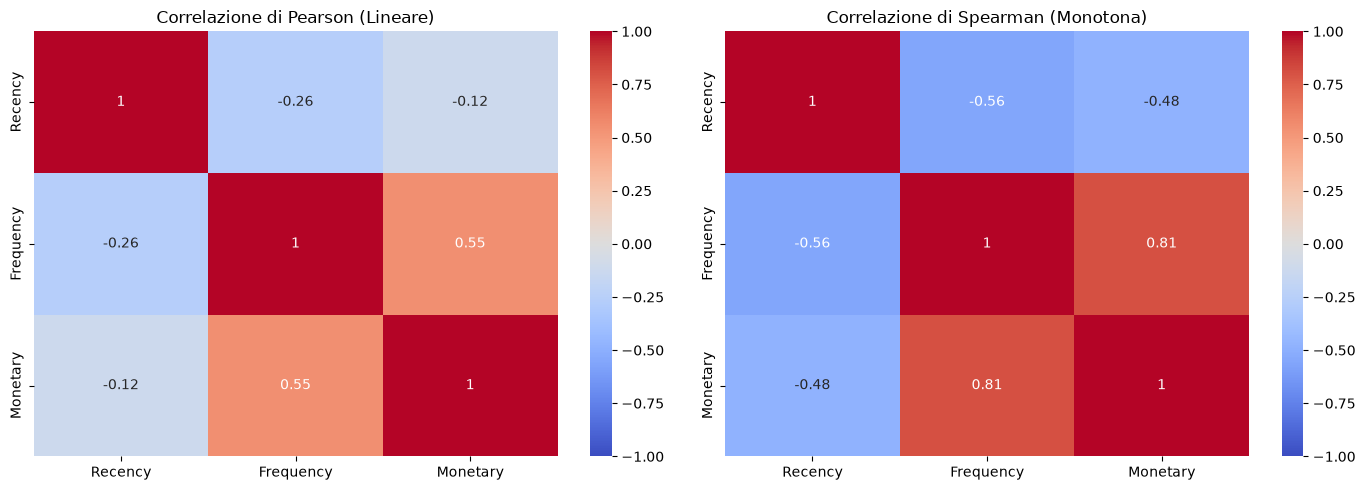

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression

# 1. Calcolo delle matrici di correlazione di Pearson e Spearman
corr_pearson = df_rfm.corr(method='pearson')
corr_spearman = df_rfm.corr(method='spearman')

# 2. Visualizzazione affiancata con Seaborn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Correlazione di Pearson (Lineare)')

sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Correlazione di Spearman (Monotona)')

plt.tight_layout()
plt.show()


In [24]:
import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression

# Inizializziamo una matrice vuota per salvare i valori di Mutual Information
mi_matrix = pd.DataFrame(index=df_rfm.columns, columns=df_rfm.columns)

# Calcoliamo la Mutual Information per ogni coppia di variabili
for col1 in df_rfm.columns:
    for col2 in df_rfm.columns:
        if col1 == col2:
            mi_matrix.loc[col1, col2] = np.nan
        else:
            # Calcolo di MI (usiamo random_state per riproducibilità)
            mi_val = mutual_info_regression(df_rfm[[col1]], df_rfm[col2], random_state=42)[0]
            mi_matrix.loc[col1, col2] = round(mi_val, 3)

mi_matrix = mi_matrix.astype(float)
mi_matrix


,Recency,Frequency,Monetary
Recency,NaN,0.242,0.140
Frequency,0.231,NaN,0.555
Monetary,0.138,0.555,NaN


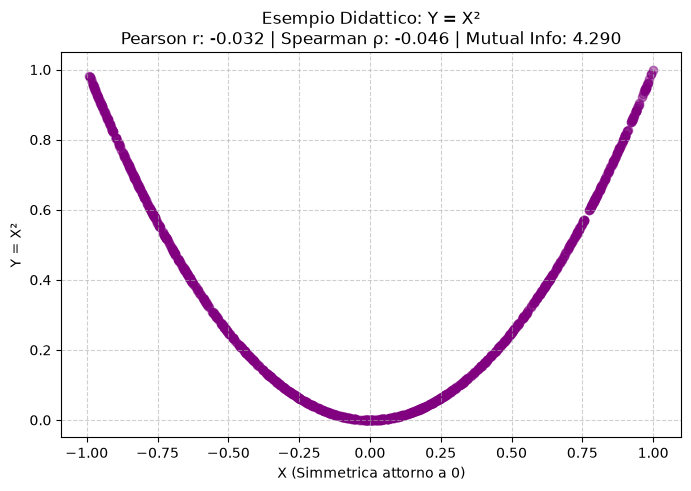

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.feature_selection import mutual_info_regression

# 1. Generiamo 1000 punti casuali per X nell'intervallo [-1, 1]
np.random.seed(42)
X_demo = np.random.uniform(-1, 1, 1000)
Y_demo = X_demo**2  # Relazione quadratica pura

# 2. Calcolo dei tre indicatori
r_val, _ = pearsonr(X_demo, Y_demo)
rho_val, _ = spearmanr(X_demo, Y_demo)
mi_demo_val = mutual_info_regression(X_demo.reshape(-1, 1), Y_demo, random_state=42)[0]

# 3. Grafico a dispersione (Scatter Plot)
plt.figure(figsize=(8, 5))
plt.scatter(X_demo, Y_demo, alpha=0.5, color='purple')
plt.title(f"Esempio Didattico: Y = X²\nPearson r: {r_val:.3f} | Spearman ρ: {rho_val:.3f} | Mutual Info: {mi_demo_val:.3f}")
plt.xlabel("X (Simmetrica attorno a 0)")
plt.ylabel("Y = X²")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Standardizzazione delle variabili RFM
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(df_rfm)

# Convertiamo in DataFrame per comodità
df_rfm_scaled = pd.DataFrame(rfm_scaled, columns=df_rfm.columns, index=df_rfm.index)

# 2. Applicazione della PCA con tutte e 3 le componenti
pca = PCA(n_components=3)
rfm_pca = pca.fit_transform(rfm_scaled)

# 3. Varianza spiegata da ciascuna componente (gli autovalori normalizzati)
var_spiegata = pca.explained_variance_ratio_
var_cumulata = np.cumsum(var_spiegata)

# Stampa dei risultati
for i, (v, c) in enumerate(zip(var_spiegata, var_cumulata), 1):
    print(f"Componente Principale {i} (PC{i}): Varianza spiegata = {v*100:.2f}% | Cumulata = {c*100:.2f}%")


Componente Principale 1 (PC1): Varianza spiegata = 55.50% | Cumulata = 55.50%
Componente Principale 2 (PC2): Varianza spiegata = 30.25% | Cumulata = 85.75%
Componente Principale 3 (PC3): Varianza spiegata = 14.25% | Cumulata = 100.00%


In [27]:
# Creiamo un DataFrame con gli autovettori (loadings)
loadings = pd.DataFrame(
    pca.components_.T, 
    columns=['PC1', 'PC2', 'PC3'], 
    index=df_rfm.columns
)

loadings


,PC1,PC2,PC3
Recency,-0.380551,0.905189,0.189248
Frequency,0.675167,0.132118,0.725737
Monetary,0.631926,0.403953,-0.661431


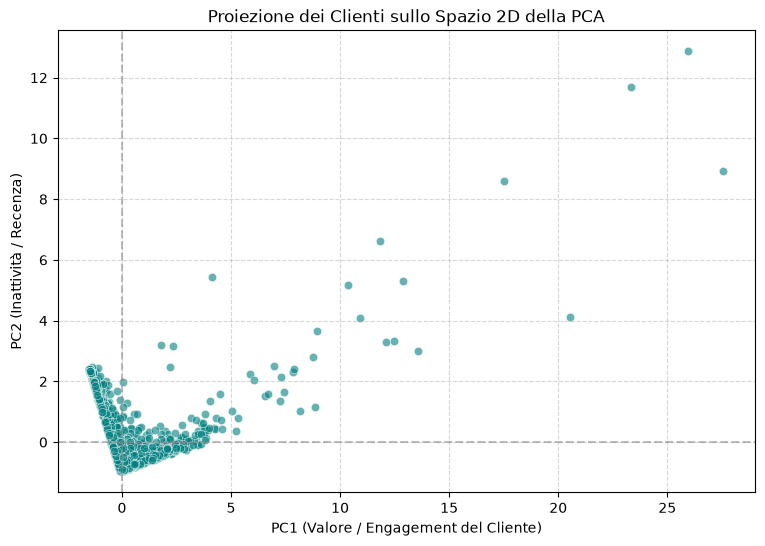

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Creiamo un DataFrame con i punteggi della PCA (i punti ruotati nello spazio 2D)
df_pca_2d = pd.DataFrame(rfm_pca[:, :2], columns=['PC1', 'PC2'], index=df_rfm.index)

# Grafico a dispersione
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_pca_2d, x='PC1', y='PC2', alpha=0.6, color='teal')
plt.title('Proiezione dei Clienti sullo Spazio 2D della PCA')
plt.xlabel('PC1 (Valore / Engagement del Cliente)')
plt.ylabel('PC2 (Inattività / Recenza)')
plt.axhline(0, color='grey', linestyle='--', alpha=0.5)
plt.axvline(0, color='grey', linestyle='--', alpha=0.5)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [30]:
import numpy as np

class KMeansFromScratch:
    def __init__(self, k=3, max_iters=100, tol=1e-4, random_state=42):
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels = None

    def fit(self, X):
        np.random.seed(self.random_state)
        N, d = X.shape
        
        # 1. Inizializzazione casuale dei centroidi scegliendo k punti del dataset
        random_indices = np.random.choice(N, self.k, replace=False)
        self.centroids = X[random_indices]
        
        for i in range(self.max_iters):
            # 2. Assignment Step: calcolo distanze e assegnazione etichette
            # Usiamo la norma euclidea vettorizzata
            distanze = np.linalg.norm(X[:, np.newaxis, :] - self.centroids[np.newaxis, :, :], axis=2)
            self.labels = np.argmin(distanze, axis=1)
            
            # 3. Update Step: ricalcolo dei centroidi
            new_centroids = np.array([X[self.labels == j].mean(axis=0) for j in range(self.k)])
            
            # 4. Controllo convergenza (distanza tra vecchi e nuovi centroidi)
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            
            if shift < self.tol:
                print(f"K-Means converge in {i+1} iterazioni!")
                break
                
        return self

# Proviamo il nostro algoritmo sui dati PCA 2D con k=3
X_pca_2d = rfm_pca[:, :2] # Consideriamo le prime due componenti
kmeans_custom = KMeansFromScratch(k=3)
kmeans_custom.fit(X_pca_2d)

print("Centroidi calcolati da zero (coppie PC1, PC2):")
print(kmeans_custom.centroids)


K-Means converge in 13 iterazioni!
Centroidi calcolati da zero (coppie PC1, PC2):
[[ 0.21795298 -0.46678077]
 [-0.92068295  1.27992163]
 [11.67604511  4.05229421]]


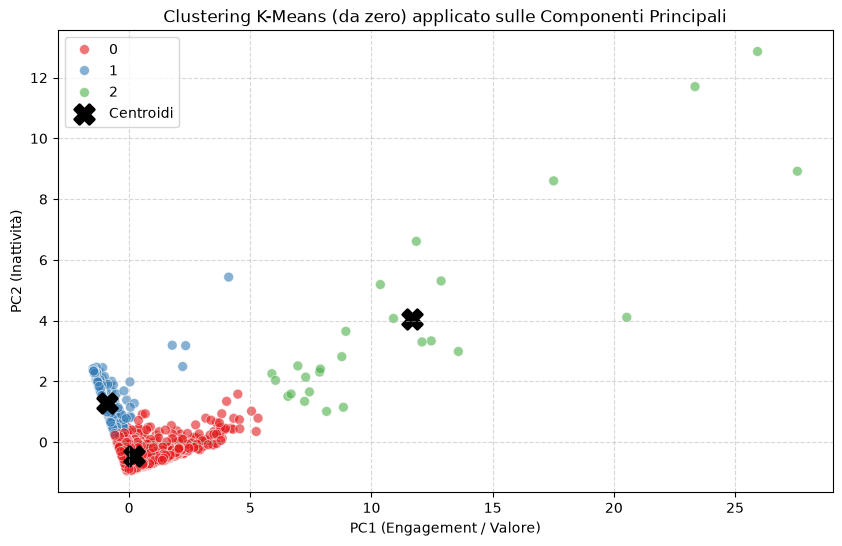

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Salviamo le etichette dei cluster nel DataFrame 2D
df_pca_2d['Cluster_Custom'] = kmeans_custom.labels

# Grafico a dispersione colorato per cluster
plt.figure(figsize=(10, 6))

# Plot dei clienti colorati in base al cluster
sns.scatterplot(
    data=df_pca_2d, 
    x='PC1', 
    y='PC2', 
    hue='Cluster_Custom', 
    palette='Set1', 
    alpha=0.6,
    s=50
)

# Plot dei 3 centroidi (disegnati come stelle rosse grandi)
plt.scatter(
    kmeans_custom.centroids[:, 0], 
    kmeans_custom.centroids[:, 1], 
    color='black', 
    marker='X', 
    s=200, 
    linewidths=2,
    label='Centroidi'
)

plt.title('Clustering K-Means (da zero) applicato sulle Componenti Principali')
plt.xlabel('PC1 (Engagement / Valore)')
plt.ylabel('PC2 (Inattività)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [32]:
import time
from sklearn.cluster import KMeans

# 1. Benchmark del K-Means fatto da zero (NumPy)
start_custom = time.time()
kmeans_custom = KMeansFromScratch(k=3, random_state=42)
kmeans_custom.fit(X_pca_2d)
time_custom = time.time() - start_custom

# 2. Benchmark del K-Means di Scikit-Learn
start_sklearn = time.time()
kmeans_sklearn = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_sklearn.fit(X_pca_2d)
time_sklearn = time.time() - start_sklearn

# 3. Stampa comparativa delle performance e dei centroidi
print(f"⏱️ Tempo K-Means Custom (NumPy): {time_custom*1000:.2f} ms")
print(f"⏱️ Tempo K-Means Scikit-Learn:  {time_sklearn*1000:.2f} ms\n")

print("Centroidi K-Means Custom:\n", kmeans_custom.centroids)
print("\nCentroidi K-Means Scikit-Learn:\n", kmeans_sklearn.cluster_centers_)


K-Means converge in 13 iterazioni!
⏱️ Tempo K-Means Custom (NumPy): 14.29 ms
⏱️ Tempo K-Means Scikit-Learn:  119.89 ms

Centroidi K-Means Custom:
 [[ 0.21795298 -0.46678077]
 [-0.92068295  1.27992163]
 [11.67604511  4.05229421]]

Centroidi K-Means Scikit-Learn:
 [[ 0.21795298 -0.46678077]
 [-0.92068295  1.27992163]
 [11.67604511  4.05229421]]


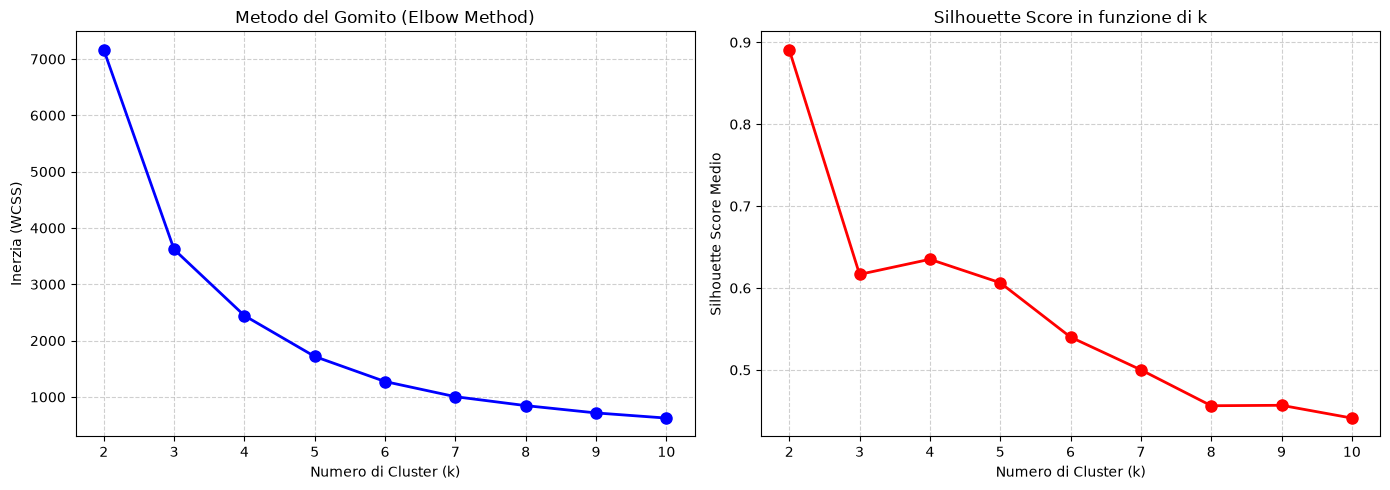

In [33]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_pca_2d)
    
    # 1. Salviamo l'inerzia (WCSS)
    wcss.append(kmeans.inertia_)
    
    # 2. Salviamo lo Silhouette Score
    score = silhouette_score(X_pca_2d, kmeans.labels_)
    silhouette_scores.append(score)

# Visualizzazione dei due grafici affiancati
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafico 1: Metodo del Gomito (WCSS)
axes[0].plot(k_range, wcss, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Metodo del Gomito (Elbow Method)')
axes[0].set_xlabel('Numero di Cluster (k)')
axes[0].set_ylabel('Inerzia (WCSS)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Grafico 2: Silhouette Score
axes[1].plot(k_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
axes[1].set_title('Silhouette Score in funzione di k')
axes[1].set_xlabel('Numero di Cluster (k)')
axes[1].set_ylabel('Silhouette Score Medio')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


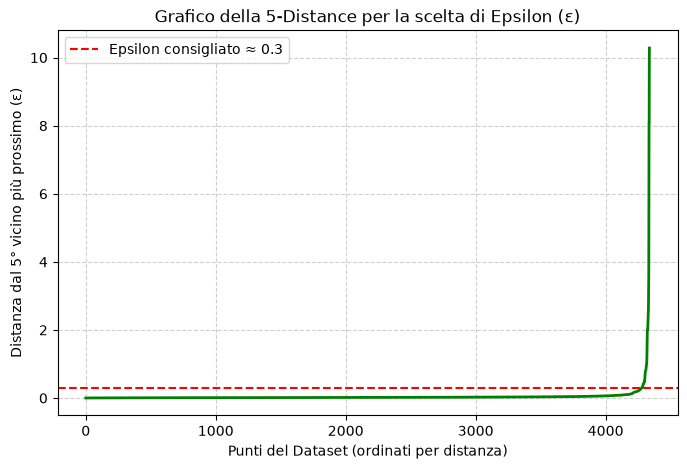

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# 1. Impostiamo min_samples = 5 e calcoliamo la distanza dai 5 vicini più prossimi
min_samples = 5
neigh = NearestNeighbors(n_neighbors=min_samples)
nbrs = neigh.fit(X_pca_2d)
distances, indices = nbrs.kneighbors(X_pca_2d)

# 2. Ordiniamo le distanze del 5° vicino in ordine crescente
# (distances[:, -1] estrae la distanza dal 5° vicino più prossimo)
k_distances = np.sort(distances[:, -1])

# 3. Grafico della k-distance per trovare epsilon (ε)
plt.figure(figsize=(8, 5))
plt.plot(k_distances, color='green', linewidth=2)
plt.title(f'Grafico della {min_samples}-Distance per la scelta di Epsilon (ε)')
plt.xlabel('Punti del Dataset (ordinati per distanza)')
plt.ylabel(f'Distanza dal {min_samples}° vicino più prossimo (ε)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(0.3, color='red', linestyle='--', label='Epsilon consigliato ≈ 0.3')
plt.legend()
plt.show()


Cluster identificati dal DBSCAN: 1
Punti identificati come Rumore/Outlier (label -1): 37



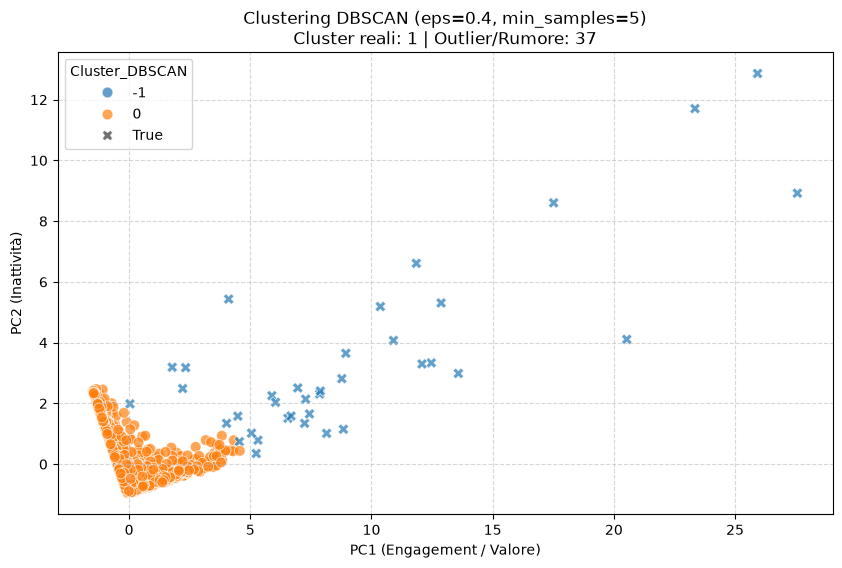

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN

# 1. Inizializzazione e fit del DBSCAN
dbscan = DBSCAN(eps=0.4, min_samples=5)
cluster_dbscan = dbscan.fit_predict(X_pca_2d)

# Salviamo le etichette nel DataFrame
df_pca_2d['Cluster_DBSCAN'] = cluster_dbscan

# 2. Numero di cluster trovati e numero di outlier (rumore)
n_clusters_ = len(set(cluster_dbscan)) - (1 if -1 in cluster_dbscan else 0)
n_noise_ = list(cluster_dbscan).count(-1)

print(f"Cluster identificati dal DBSCAN: {n_clusters_}")
print(f"Punti identificati come Rumore/Outlier (label -1): {n_noise_}\n")

# 3. Grafico dei cluster DBSCAN
plt.figure(figsize=(10, 6))

# Usiamo una tavolozza dove il rumore (-1) viene evidenziato in grigio/nero
sns.scatterplot(
    data=df_pca_2d, 
    x='PC1', 
    y='PC2', 
    hue='Cluster_DBSCAN', 
    palette='tab10', 
    style=(df_pca_2d['Cluster_DBSCAN'] == -1), # Cambia forma agli outlier
    markers={True: 'X', False: 'o'},
    alpha=0.7,
    s=60
)

plt.title(f'Clustering DBSCAN (eps=0.4, min_samples=5)\nCluster reali: {n_clusters_} | Outlier/Rumore: {n_noise_}')
plt.xlabel('PC1 (Engagement / Valore)')
plt.ylabel('PC2 (Inattività)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


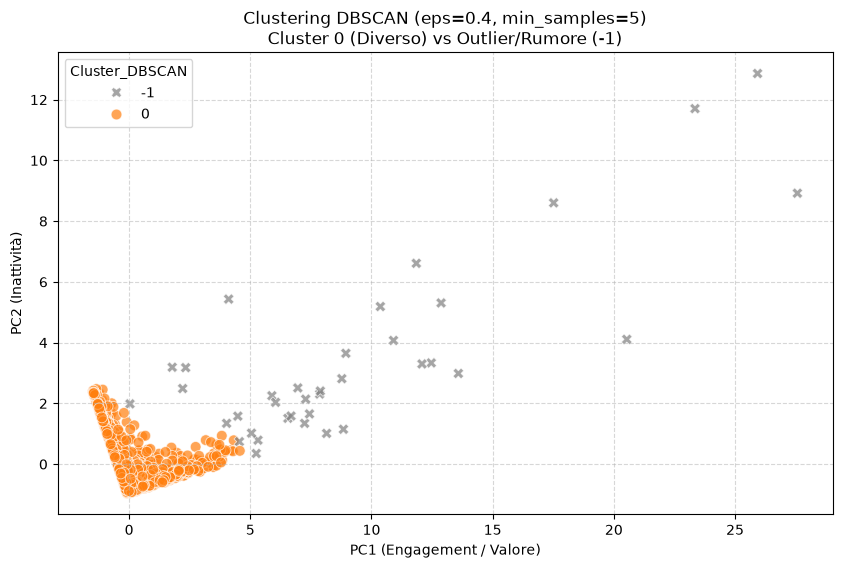

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# Usiamo una tavolozza personalizzata: grigio per -1, arancione per 0
palette_custom = {-1: 'tab:gray', 0: 'tab:orange', 1: 'tab:blue', 2: 'tab:green'}

sns.scatterplot(
    data=df_pca_2d, 
    x='PC1', 
    y='PC2', 
    hue='Cluster_DBSCAN', 
    style='Cluster_DBSCAN',
    palette=palette_custom,
    markers={-1: 'X', 0: 'o', 1: 's', 2: 'D'},
    alpha=0.7,
    s=60
)

plt.title(f'Clustering DBSCAN (eps=0.4, min_samples=5)\nCluster 0 (Diverso) vs Outlier/Rumore (-1)')
plt.xlabel('PC1 (Engagement / Valore)')
plt.ylabel('PC2 (Inattività)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [37]:
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import KMeans

# --- A. VERIFICA DELLA STABILITÀ CON ARI ---
# Estraiamo un sottocampione casuale dell'80% dei clienti
np.random.seed(42)
sample_indices = np.random.choice(len(X_pca_2d), size=int(0.8 * len(X_pca_2d)), replace=False)

X_sample = X_pca_2d[sample_indices]
labels_original = kmeans_sklearn.labels_[sample_indices]

# Eseguiamo il K-Means sul sottocampione
kmeans_sample = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_sample = kmeans_sample.fit_predict(X_sample)

ari_score = adjusted_rand_score(labels_original, labels_sample)
print(f"Stabilità dei Cluster (Adjusted Rand Index - ARI): {ari_score:.3f}")

# --- B. PROFILAZIONE DI BUSINESS SULLE VARIABILI REALI (R, F, M) ---
df_rfm['Cluster'] = kmeans_sklearn.labels_

profilo_clusters = df_rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)

print("\n--- PROFILO MEDIO DEI CLUSTER (Valori Reali) ---")
profilo_clusters


Stabilità dei Cluster (Adjusted Rand Index - ARI): 0.996

--- PROFILO MEDIO DEI CLUSTER (Valori Reali) ---


Recency Frequency  Monetary      
           mean      mean      mean count
Cluster                                  
0         41.15      4.68   1859.72  3220
1        246.11      1.58    631.51  1092
2          6.04     66.42  85904.35    26